# Plots: LSVSC female stratified subset (2,000 files)

Visualize the 2,000-file dataset using its simplified metadata.

In [1]:
from pathlib import Path
import wave

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
ROOT = Path('LSVSC_female_stratified_2000')
df = pd.read_csv(ROOT / 'metadata.csv')
assert len(df) == 2000, f'Expected 2,000 rows, found {len(df):,}'
assert df['gender'].eq('female').all(), 'Non-female records found'
assert df['file_id'].tolist() == list(range(1, 2001)), 'File IDs are not sequential'
print(f'WAV files: {len(df):,}')
display(df.head())

WAV files: 2,000


,file_id,relative_path,gender,transcription,age,region
0,1,audio/000001.wav,female,Khánh Ly rất là thích khoảng thời gian này khi...,middle age,Trung
1,2,audio/000002.wav,female,Điểm mới của Nghị quyết này là Quốc hội quyết ...,middle age,Trung
2,3,audio/000003.wav,female,để đầu tư cơ sở hạ tầng kinh tế xã hội và các ...,middle age,Trung
3,4,audio/000004.wav,female,Thị trường lao động của vùng tuy đã có phát tr...,middle age,Trung
4,5,audio/000005.wav,female,"Đồng thời, các vị diễn giả cũng chia sẻ những ...",middle age,Trung


In [2]:
def duration_seconds(relative_path):
    with wave.open(str(ROOT / relative_path), 'rb') as audio:
        return audio.getnframes() / audio.getframerate()

df['duration_s'] = df['relative_path'].map(duration_seconds)
df['transcription_length'] = df['transcription'].fillna('').str.len()
summary = pd.DataFrame({
    'WAV files': [len(df)],
    'Total duration (minutes)': [df['duration_s'].sum() / 60],
    'Mean duration (seconds)': [df['duration_s'].mean()],
    'Median duration (seconds)': [df['duration_s'].median()],
    'Age groups': [df['age'].nunique()],
    'Mean transcription length': [df['transcription_length'].mean()]
}).round(2)
display(summary)

,WAV files,Total duration (minutes),Mean duration (seconds),Median duration (seconds),Age groups,Mean transcription length
0,2000,215.74,6.47,6.29,5,114.63


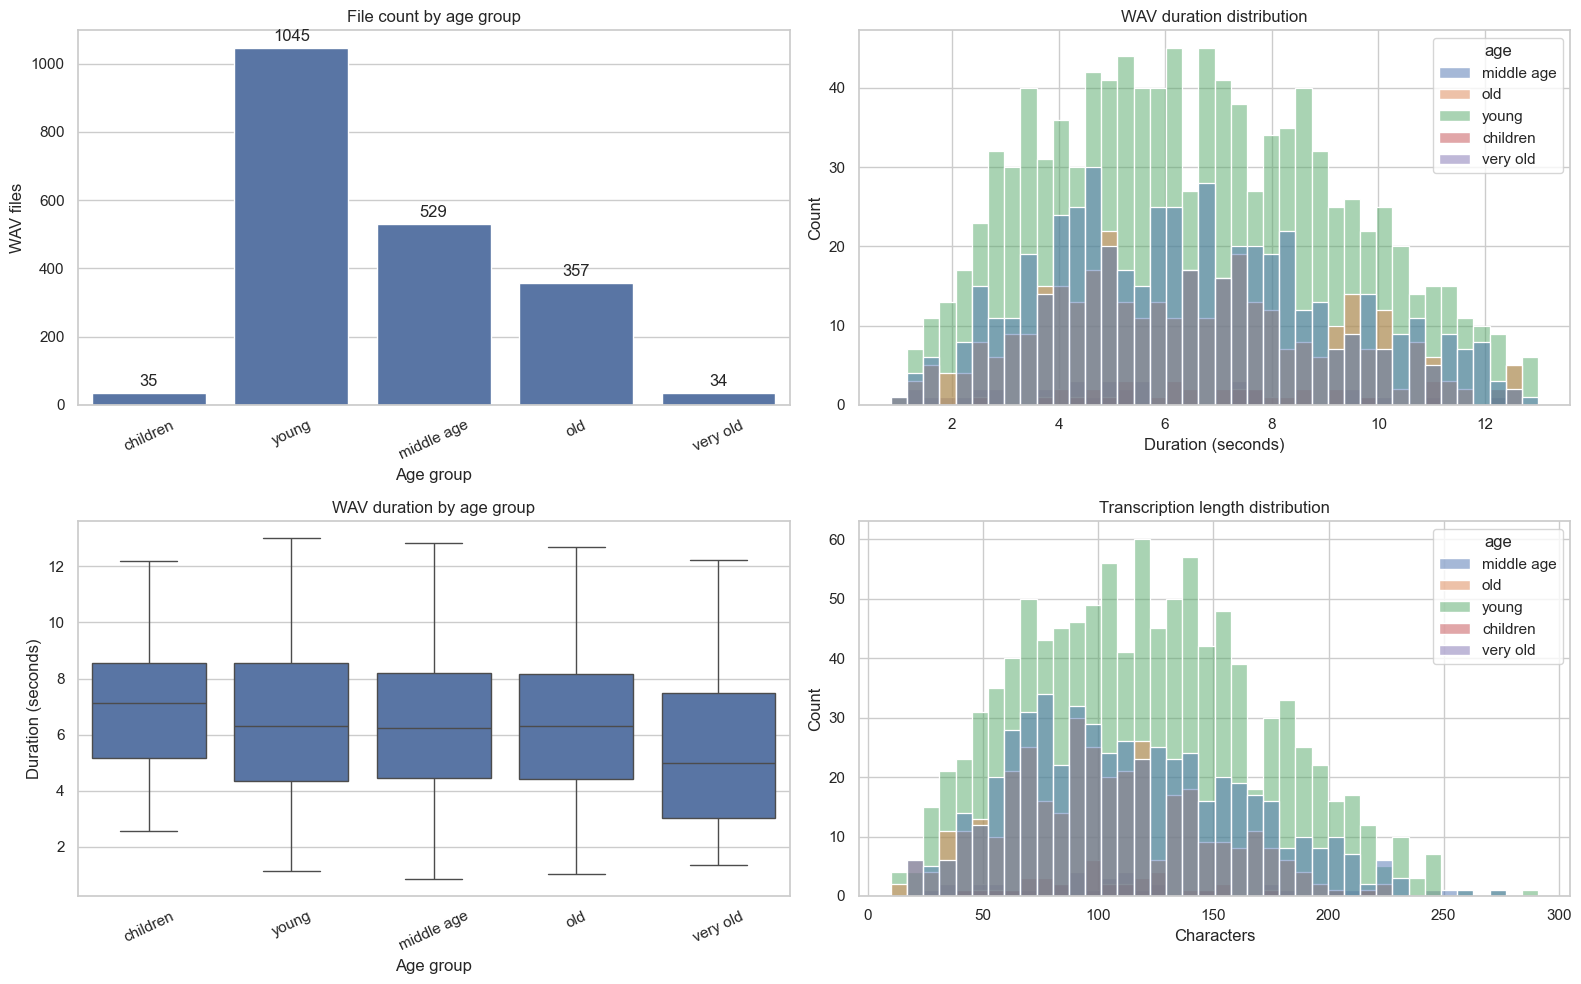

In [3]:
age_order = ['children', 'young', 'middle age', 'old', 'very old']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.countplot(data=df, x='age', order=age_order, ax=axes[0, 0])
axes[0, 0].set_title('File count by age group')
axes[0, 0].set_xlabel('Age group')
axes[0, 0].set_ylabel('WAV files')
axes[0, 0].tick_params(axis='x', rotation=25)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt='%d', padding=3)

sns.histplot(data=df, x='duration_s', hue='age', bins=40, multiple='layer', ax=axes[0, 1])
axes[0, 1].set_title('WAV duration distribution')
axes[0, 1].set_xlabel('Duration (seconds)')

sns.boxplot(data=df, x='age', y='duration_s', order=age_order, ax=axes[1, 0])
axes[1, 0].set_title('WAV duration by age group')
axes[1, 0].set_xlabel('Age group')
axes[1, 0].set_ylabel('Duration (seconds)')
axes[1, 0].tick_params(axis='x', rotation=25)

sns.histplot(data=df, x='transcription_length', hue='age', bins=40, multiple='layer', ax=axes[1, 1])
axes[1, 1].set_title('Transcription length distribution')
axes[1, 1].set_xlabel('Characters')

plt.tight_layout()
plt.show()

In [4]:
age_summary = df.groupby('age').agg(
    files=('file_id', 'size'),
    mean_duration_s=('duration_s', 'mean'),
    median_duration_s=('duration_s', 'median'),
    mean_transcription_length=('transcription_length', 'mean'),
).reindex(age_order).round(2)
display(age_summary)

df.to_csv(ROOT / 'metadata_with_duration.csv', index=False, encoding='utf-8-sig')

,files,mean_duration_s,median_duration_s,mean_transcription_length
age,,,,
children,35,7.13,7.12,105.31
young,1045,6.52,6.32,119.62
middle age,529,6.46,6.25,114.36
old,357,6.39,6.32,102.23
very old,34,5.48,4.99,105.44
